# 3 · Check And Explain

<a href="https://colab.research.google.com/github/FH-Prevail/steyr_course/blob/main/notebooks/3_check_and_explain.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

*Advanced Data Analysis Techniques · Session 4: Forecasting With Tree-Based Models · Sina Mirshahi, FH OÖ Steyr*


**Hands-on 3.** Before you trust a forecast, check it; before you use it, understand it. You will

- check code that an AI assistant wrote, and find out why its result is too good to be true,
- see what a tree does with weeks unlike anything it has seen,
- ask the model what it relies on, how the temperature effect bends, and why one forecast is what it is,
- ask the model what-if questions.


**How to work with this notebook**

1. In Colab choose **File, Save a copy in Drive**. Your copy keeps your changes; this original never changes.
2. Run the cells from the top with **Shift + Enter**, or all at once with **Runtime, Run all**.
3. Read the result under each cell before you go on. You do not need to write code from scratch.

| Label | Meaning |
|---|---|
| `# EDIT` | a setting you may change, then run the cell again |
| `# CHECK` | the result for the unchanged course data; after an EDIT the numbers change, and that is fine |
| **Ask an AI** | a prompt that writes the same code in Gemini, ChatGPT or Claude, and how to check its answer |
| **Your answer** | a few words of your own: double-click the cell, write, then Shift + Enter |

The data is synthetic: a drinks wholesaler in Upper Austria, built to look like real weekly sales. No company data is contained.

In [1]:
# Start here: run this cell first. It loads the course data (one small table) and sets up the charts.
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DATA = "https://raw.githubusercontent.com/FH-Prevail/steyr_course/main/data"   # the course data on GitHub
if Path("data/drinks_weekly.csv").exists():      # a copy next to the notebook (Google Drive or upload) is used first
    DATA = "data"
sales = pd.read_csv(f"{DATA}/drinks_weekly.csv", parse_dates=["week_start"])
sales["product"] = sales["product"].astype(object)   # plain text labels: the regression formula works with every pandas version

# one colour per method, the same as on the slides
COLOURS = {"Actual sales": "#262626", "Repeat last year": "#E66A1F", "Linear regression": "#1B9E5A",
           "Decision tree": "#7A5C00", "Random forest": "#D04F95", "LightGBM": "#0B5CAD"}
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.float_format", "{:,.1f}".format)
print("Ready:", len(sales), "rows,", sales["product"].nunique(), "products, weeks from",
      sales["week_start"].min().date(), "to", sales["week_start"].max().date())
# CHECK: Ready: 1672 rows, 8 products, weeks from 2022-01-03 to 2025-12-29

Ready: 1672 rows, 8 products, weeks from 2022-01-03 to 2025-12-29


In [2]:
# Rebuild notebook 2 in one go: inputs, the time split and the models with the knobs chosen there on 2024 (a few seconds).
import statsmodels.formula.api as smf
from sklearn.ensemble import RandomForestRegressor
from lightgbm import LGBMRegressor

sales = sales.sort_values(["product", "week_start"]).reset_index(drop=True)
for product, part in sales.groupby("product"):                     # every week once, no gaps, before shifting
    assert (part["week_start"].diff().dropna() == pd.Timedelta(days=7)).all(), product
by_product = sales.groupby("product")["units"]
sales["last_week"] = by_product.shift(1)
sales["avg_last_4"] = by_product.transform(lambda s: s.shift(1).rolling(4).mean())
sales["same_week_last_year"] = by_product.shift(52)
sales["week_of_year"] = sales["week_start"].dt.isocalendar().week.astype(int)

FEATURES = ["product", "week_of_year", "temp_forecast", "discount_pct", "holiday_days",
            "last_week", "avg_last_4", "same_week_last_year"]
PRODUCTS = sorted(sales["product"].unique())
COLUMNS = FEATURES[1:] + ["product_" + p.replace(" ", "_") for p in PRODUCTS]


def encode(table, features=FEATURES):
    """The model inputs as numbers: the inputs, plus one 0/1 column per product."""
    X = pd.get_dummies(table[features], columns=["product"], dtype=int)
    X.columns = [c.replace(" ", "_") for c in X.columns]
    return X.reindex(columns=[c for c in COLUMNS if c in X.columns or c.startswith("product_")], fill_value=0)


def score(actual, forecast):
    """Three numbers for a forecast. MAE: the average miss in cases. WAPE: all misses added up, as a
    percentage of all cases sold. Bias: forecast minus actual, on average (minus means too low)."""
    if isinstance(actual, pd.Series) and isinstance(forecast, pd.Series):
        assert actual.index.equals(forecast.index), "Actuals and forecasts must belong to the same weeks."
    a, f = np.asarray(actual, dtype=float), np.asarray(forecast, dtype=float)
    assert a.ndim == 1 and a.size > 0 and a.shape == f.shape, "One forecast for every week, in one column."
    assert np.isfinite(a).all() and np.isfinite(f).all(), "Every week needs a number: no missing actual or forecast."
    miss, total = f - a, np.abs(a).sum()
    return pd.Series({"MAE, cases": np.abs(miss).mean(),
                      "WAPE, %": np.abs(miss).sum() / total * 100 if total else np.nan,   # undefined if nothing was sold
                      "Bias, cases": miss.mean()})


data = sales.dropna(subset=["same_week_last_year"])
train = data[data["week_start"].dt.year <= 2024]
test = data[data["week_start"].dt.year == 2025].copy()
X_train, y_train, X_test, y_test = encode(train), train["units"], encode(test), test["units"]
reg = smf.ols("units ~ C(product) + week_of_year + temp_forecast + discount_pct + holiday_days"
              " + last_week + avg_last_4 + same_week_last_year", data=train).fit()
forest = RandomForestRegressor(n_estimators=300, max_features=0.33, random_state=42, n_jobs=-1).fit(X_train, y_train)
boost = LGBMRegressor(n_estimators=400, learning_rate=0.05, num_leaves=7, min_child_samples=10,
                      random_state=42, verbose=-1).fit(X_train, y_train)
test["Linear regression"], test["Random forest"], test["LightGBM"] = reg.predict(test), forest.predict(X_test), boost.predict(X_test)
print("LightGBM, WAPE on 2025:", round(score(y_test, test["LightGBM"])["WAPE, %"], 1), "%")
# CHECK: LightGBM, WAPE on 2025: 14.8 %

LightGBM, WAPE on 2025: 14.8 %


## 1. An AI's answer to check

I asked an AI assistant: *"Here is drinks_weekly.csv with weekly sales per product. Write Python code that forecasts the weekly cases with a random forest and tells me how accurate it is."* This is its answer, unchanged. Run it.

In [3]:
# ---------------- code written by an AI assistant, unchanged ----------------
from sklearn.model_selection import train_test_split

df = pd.read_csv(f"{DATA}/drinks_weekly.csv", parse_dates=["week_start"])
df = df.sort_values(["product", "week_start"])
df["week_of_year"] = df["week_start"].dt.isocalendar().week.astype(int)
df["last_week"] = df.groupby("product")["units"].shift(1)
df = df.dropna()

X = pd.get_dummies(df.drop(columns=["units", "week_start"]), columns=["product"], dtype=int)
y = df["units"]
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, random_state=42)
model = RandomForestRegressor(n_estimators=300, random_state=42, n_jobs=-1).fit(X_tr, y_tr)
pred = model.predict(X_te)
print("WAPE:", round(np.abs(pred - y_te).sum() / y_te.sum() * 100, 1), "%. An excellent forecast!")
# -----------------------------------------------------------------------------
# CHECK: WAPE: 2.5 %

WAPE: 2.5 %. An excellent forecast!


**Too good to be true?** Our best honest model in notebook 2 missed 14.8 % of the cases, repeating last year 29.1 %. The AI's forest claims 2.5 % with less effort. Before you celebrate, run the checks.

**Check 1: what does the model rely on?** A random forest records how much each input helped its questions.

In [4]:
shares = pd.Series(model.feature_importances_, index=X.columns) * 100      # percent of all the importance
shares.sort_values(ascending=False).head(6)
# CHECK: pallets comes first, with 83.1 % of all the importance

pallets                 83.1
product_Mineral water    6.8
last_week                6.7
product_Radler           1.1
discount_pct             0.8
temp_actual              0.4
dtype: float64

**Check 2: is every input known on Sunday evening?** `X` holds every column except `units` and `week_start`:

| Input | Known on Sunday evening? |
|---|---|
| `pallets` | **no**: the pallets picked for these very cases, the answer in another unit (cases ÷ cases per pallet) |
| `temp_actual` | **no**: the weather that came, known only after the week |
| `temp_forecast`, `discount_pct`, `holiday_days`, `week_of_year`, `last_week`, product | yes |

This is the overlap test from session 2: *does the input measure the outcome itself?*

**Check 3: how was it tested?** `train_test_split` picks test weeks at random, so the model learned from weeks after the ones it forecasts.

Now fix it: drop the two columns that are unknown on Sunday, then split by time.

In [5]:
honest = df.drop(columns=["pallets", "temp_actual"])                          # only what we know on Sunday
X_h = pd.get_dummies(honest.drop(columns=["units", "week_start"]), columns=["product"], dtype=int)
steps = {"AI's code": round(np.abs(pred - y_te).sum() / y_te.sum() * 100, 1)}

X_tr, X_te, y_tr, y_te = train_test_split(X_h, y, test_size=0.2, random_state=42)      # still a random split
p = RandomForestRegressor(n_estimators=300, random_state=42, n_jobs=-1).fit(X_tr, y_tr).predict(X_te)
steps["without pallets and temp_actual"] = round(np.abs(p - y_te).sum() / y_te.sum() * 100, 1)

past, future = honest["week_start"].dt.year <= 2024, honest["week_start"].dt.year == 2025   # split by time
p = RandomForestRegressor(n_estimators=300, random_state=42, n_jobs=-1).fit(X_h[past], y[past]).predict(X_h[future])
steps["... and split by time"] = round(np.abs(p - y[future]).sum() / y[future].sum() * 100, 1)
pd.Series(steps, name="WAPE, %")
# CHECK: 2.5 %, then 14.2 %, then 15.5 %

AI's code                          2.5
without pallets and temp_actual   14.2
... and split by time             15.5
Name: WAPE, %, dtype: float64

**What to see.** Without the answer hidden in `pallets`, the error on the same random test weeks jumps from 2.5 % to 14.2 %. Tested on 2025 after learning from the years before, it is 15.5 %: an honest historical test, though not a promise for next year. (This repaired version keeps the AI's own inputs and learns from 2022 to 2024, so it differs a little from notebook 2.) The code ran without a single error message: **code that runs is not code that is right.**

> **Ask an AI, the better way** · *"I forecast next week's cases per product every Sunday evening. drinks_weekly.csv has one row per product and week. Sort by product and date, then build the inputs: week of the year, temp_forecast, discount_pct, holiday_days, last week's sales via shift(1) per product, and the benchmark, sales 52 rows back per product. Do not use pallets or temp_actual: they are known only after the week. Train a random forest on 2023 and 2024, test it on 2025, and compare its WAPE with the benchmark's. Print the date range of both parts, the WAPE on the training and the test years, and a chart of actual against forecast for one product. Ask me if anything is unclear instead of guessing."*
> **Check:** the five checks from the slides: split by time, every input known on Sunday, a benchmark, the error on seen against new weeks, and a look at the forecast chart.

## 2. Weeks unlike the past

A tree answers with averages of weeks it has seen. What happens when a week looks like none of them?

**The growing product.** The energy drink sells more every year. A forest without the history inputs knows only the calendar, the weather and the promotions:

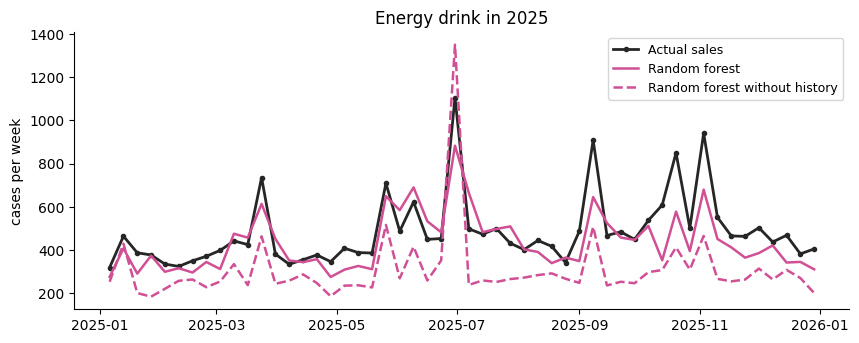

2025 average: 484 | forest: 436 | without history: 308 | highest week in 2023-24: 771


In [6]:
from sklearn.base import clone

no_history = ["product", "week_of_year", "temp_forecast", "discount_pct", "holiday_days"]
forest_nh = clone(forest)                                        # the same settings, only the inputs differ
forest_nh.fit(encode(train, no_history), y_train)
test["Forest without history"] = forest_nh.predict(encode(test, no_history))

energy = test[test["product"] == "Energy drink"]
fig, ax = plt.subplots(figsize=(10, 3.6))
ax.plot(energy["week_start"], energy["units"], color=COLOURS["Actual sales"], lw=2, marker="o", ms=3, label="Actual sales")
ax.plot(energy["week_start"], energy["Random forest"], color=COLOURS["Random forest"], lw=1.8, label="Random forest")
ax.plot(energy["week_start"], energy["Forest without history"], color=COLOURS["Random forest"], lw=1.8, ls="--",
        label="Random forest without history")
ax.set(title="Energy drink in 2025", ylabel="cases per week")
ax.legend(fontsize=9)
plt.show()
print("2025 average:", round(energy["units"].mean()), "| forest:", round(energy["Random forest"].mean()),
      "| without history:", round(energy["Forest without history"].mean()),
      "| highest week in 2023-24:", train.loc[train["product"] == "Energy drink", "units"].max())
# CHECK: 2025 average: 484 | forest: 436 | without history: 308

**What to see.** Without the history inputs the forest stays near the level of 2023 and 2024: a tree forecasts averages of training weeks (in a model for all products, those can include weeks of other products), so it does not continue a trend by itself. With last week and the last four weeks as inputs it follows the growth most of the way; the inputs carry the new level. **Give a tree the recent level, or let it forecast the change, when a series grows.**

**The record heat.** The week of 30 June 2025 had a forecast of 35.8 °C, hotter than any week the models learned from (at most 31.9 °C):

In [7]:
heat = test[test["week_start"].isin(pd.to_datetime(["2025-06-23", "2025-06-30", "2025-07-07"]))
            & test["product"].isin(["Ice tea", "Mineral water"])]
print("Hottest forecast in 2023-24:", train["temp_forecast"].max(), "°C")
heat[["week_start", "product", "temp_forecast", "discount_pct", "units", "Linear regression", "LightGBM"]].round({"Linear regression": 0, "LightGBM": 0})
# CHECK: ice tea in the week of 30 June: 3948 cases sold, LightGBM 2395

Hottest forecast in 2023-24: 31.9 °C


,week_start,product,temp_forecast,discount_pct,units,Linear regression,LightGBM
599,2025-06-23,Ice tea,32.8,0,1464,"1,102.0","1,404.0"
600,2025-06-30,Ice tea,35.8,20,3948,"1,822.0","2,395.0"
601,2025-07-07,Ice tea,28.4,0,1330,"1,584.0","1,013.0"
1017,2025-06-23,Mineral water,32.8,0,4593,"4,893.0","3,700.0"
1018,2025-06-30,Mineral water,35.8,0,4405,"3,825.0","3,736.0"
1019,2025-07-07,Mineral water,28.4,0,4167,"3,482.0","3,236.0"


**What to see.** In the record week, with a promotion on top, ice tea sold 3948 cases; LightGBM forecast 2395. LightGBM adds up the corrections of many trees, so it can step a little outside the sales it has seen; but once the temperature is beyond its hottest learned split, more heat no longer changes its forecast. No week in the training data looked like this one. Flag weeks unlike the past (record weather, a first-time promotion, a new product) and plan them with judgement on top of the model.

## 3. What the model relies on

**Permutation importance:** shuffle one input in the 2025 weeks, so its values no longer belong to their weeks, and see how much the WAPE rises. A big rise means the model relies on that input for its 2025 forecasts. Each input is shuffled **within the same product**, so radler never gets the sales scale of mineral water; the product itself is swapped between rows. Shuffling can still create unusual weeks (summer weather with a winter history), and inputs that carry the same information can stand in for each other, so a small value does not prove an input useless.

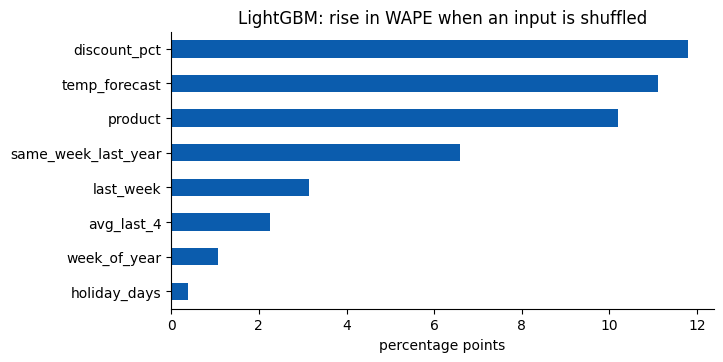

discount_pct          11.8
temp_forecast         11.1
product               10.2
same_week_last_year    6.6
last_week              3.1
avg_last_4             2.3
week_of_year           1.1
holiday_days           0.4
dtype: float64

In [8]:
def importance(model, table, repeats=3):
    """How much the WAPE on `table` rises when one input is shuffled (average of a few shuffles)."""
    base = score(table["units"], model.predict(encode(table)))["WAPE, %"]
    rng = np.random.default_rng(0)
    rise = {}
    for feature in FEATURES:
        rises = []
        for _ in range(repeats):
            shuffled = table.copy()
            if feature == "product":                     # swap the product between rows
                shuffled[feature] = rng.permutation(shuffled[feature].to_numpy())
            else:                                        # shuffle within each product
                for _, idx in shuffled.groupby("product").groups.items():
                    shuffled.loc[idx, feature] = rng.permutation(shuffled.loc[idx, feature].to_numpy())
            rises.append(score(table["units"], model.predict(encode(shuffled)))["WAPE, %"] - base)
        rise[feature] = np.mean(rises)
    return pd.Series(rise).sort_values()


relies = importance(boost, test)
relies.plot.barh(color="#0B5CAD", figsize=(7, 3.6), title="LightGBM: rise in WAPE when an input is shuffled")
plt.xlabel("percentage points")
plt.show()
relies.sort_values(ascending=False).round(1)
# CHECK: the three largest: discount_pct, temp_forecast, product

**What to see.** The model relies most on the planned discount and the temperature forecast, then on which product it is and on last year's level. These are the habits of this fitted model in its 2025 forecasts, not proof of what causes demand. If an input you know to be irrelevant ranks high, look for a leak (as with `pallets` above).

## 4. OPTIONAL: how the forecast changes with the temperature

Take one real week per product, change only the temperature forecast, and ask the model again for every temperature from -5 to 35 °C. These curves describe the model for these weeks, not what temperature causes; some combinations (frost with an August sales history) never happen. The regression of session 2 answers with one straight line and the same slope for every product.

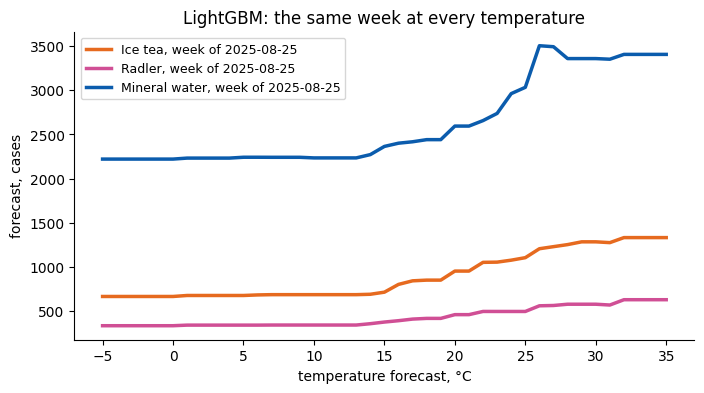

      product  at 10 °C  at 30 °C
      Ice tea     686.0   1,284.0
       Radler     342.0     577.0
Mineral water   2,234.0   3,359.0
The regression: one degree warmer adds 11.1 cases, for every product


In [9]:
weeks = {"Ice tea": "2025-08-25", "Radler": "2025-08-25", "Mineral water": "2025-08-25"}   # EDIT: product and week
temps = np.arange(-5, 36)
PRODUCT_COLOURS = {"Mineral water": "#0B5CAD", "Ice tea": "#E66A1F", "Mulled wine": "#1B9E5A", "Radler": "#D04F95"}

fig, ax = plt.subplots(figsize=(8, 4))
checks = []
for product, week in weeks.items():
    row = test[(test["product"] == product) & (test["week_start"] == week)]
    assert len(row) == 1, f"Choose a product and a Monday of 2025 that exist: {product}, {week}"
    what_if = pd.concat([row] * len(temps), ignore_index=True)
    what_if["temp_forecast"] = temps
    forecast = boost.predict(encode(what_if))
    ax.plot(temps, forecast, color=PRODUCT_COLOURS.get(product, "#595959"), lw=2.5, label=f"{product}, week of {week}")
    checks.append({"product": product, "at 10 °C": forecast[temps == 10][0], "at 30 °C": forecast[temps == 30][0]})
ax.set(xlabel="temperature forecast, °C", ylabel="forecast, cases", title="LightGBM: the same week at every temperature")
ax.legend(fontsize=9)
plt.show()
print(pd.DataFrame(checks).round(0).to_string(index=False))
print("The regression: one degree warmer adds", round(reg.params["temp_forecast"], 1), "cases, for every product")
# CHECK: the regression: one degree warmer adds 11.1 cases, for every product

**What to see.** Read the printed forecasts at 10 and 30 °C: each product has its own curve, flat in the cold and climbing in summer temperatures. The regression gives one number per input, 11.1 cases per degree, the same for every product and every temperature. **A tree model gives each product its own curve.** Beyond about 32 °C every curve goes flat: the model has never seen hotter weeks. The curves need not rise steadily; small dips are the model's steps, not a business effect.

Mulled wine is missing on purpose. The models have seen only two Advent seasons, about a dozen weeks: too few to learn how the cold moves its sales. Few examples, no reliable pattern.

## 5. One forecast explained

LightGBM can split one forecast into a **reference**, the model's average forecast over the training weeks, plus one share per input, in cases. These shares are called **SHAP values**; reference plus shares give exactly the forecast. They describe how the model built this number, not what would happen if you changed an input (that is the what-if question of section 6).

In [10]:
product, week = "Radler", "2025-06-23"                      # EDIT: any product and any Monday of 2025
row = test[(test["product"] == product) & (test["week_start"] == week)]
assert len(row) == 1, "Choose a product and a Monday of 2025 that exist."

parts = pd.Series(boost.predict(encode(row), pred_contrib=True)[0], index=COLUMNS + ["reference: average forecast"])
assert np.isclose(parts.sum(), boost.predict(encode(row))[0])          # reference plus shares = the forecast
product_columns = [c for c in COLUMNS if c.startswith("product_")]
parts["product"] = parts[product_columns].sum()              # the eight 0/1 columns as one line
parts = parts.drop(product_columns)
values = row[FEATURES].iloc[0]
table = pd.DataFrame({"value this week": [values.get(i, "") for i in parts.index], "share, cases": parts.round(0)})
print(f"{product}, week of {week}: forecast {parts.sum():,.0f} cases, actual {row['units'].iloc[0]:,} cases")
table.sort_values("share, cases", key=abs, ascending=False)
# CHECK: Radler, week of 2025-06-23: forecast 2,214 cases, actual 2,122 cases

Radler, week of 2025-06-23: forecast 2,214 cases, actual 2,122 cases


,value this week,"share, cases"
reference: average forecast,,859.0
discount_pct,20,765.0
temp_forecast,32.8,411.0
same_week_last_year,"1,149.0",315.0
product,Radler,-146.0
last_week,906.0,101.0
week_of_year,26,-64.0
avg_last_4,981.8,-35.0
holiday_days,0,7.0


**How to read it.** The reference is the model's average forecast. Each line moves this week's forecast up or down from there; the shares add up to the forecast. In a meeting: *"Our model forecasts about 2,214 cases of Radler. Compared with its average week, it attributes about 765 cases to the planned 20 % promotion and about 411 to the 33 °C forecast."* Change the week and the product, and explain another forecast.

## 6. OPTIONAL: what if?

The model answers questions a planner asks every week: what if we skip the promotion, what if the heat breaks and the week stays cool? These are the model's forecasts under other inputs, with everything else kept; they are not proof of cause. Note that "without the promotion" changes the forecast by more than the promotion's SHAP share above: the two answer different questions.

In [11]:
plans = {"as planned": row.copy(), "without the promotion": row.copy(), "a cool week, 18 °C": row.copy()}
plans["without the promotion"]["discount_pct"] = 0                                    # EDIT: 0, 10, 20 or 30
plans["a cool week, 18 °C"]["temp_forecast"] = 18                                     # EDIT: any temperature
for name, plan in plans.items():
    print(f"{name:27s}", round(boost.predict(encode(plan))[0]), "cases")
# CHECK: as planned 2214, without the promotion 1014, a cool week 1649

as planned                  2214 cases
without the promotion       1014 cases
a cool week, 18 °C          1649 cases


### Your answer (not graded; it prepares your project)

1. Name the two inputs in the AI's code that are unknown on Sunday evening, and say how you found the first one. ___
2. Why does a forest without the history inputs fail on the energy drink? ___
3. Write the meeting sentence for one forecast of your choice from section 5: *"Our model forecasts ___ cases of ___ for the week of ___; compared with its average week, it attributes the most to ___."*